# Figure 5c. Pathway enrichment of microglia *trans*-eProgram 31

Over-representation analysis of the member genes of microglia *trans*-eProgram 31 (Hotspot module 31). The x-axis is -log10 of the nominal ORA p-value and point size is the number of program genes in the pathway. The five pathways shown were selected by the authors from the 59 pathways in the ORA output (their p-value ranks are 1, 5, 7, 9 and 16, stored in `rank_by_p`); all five have q < 0.05.

Input: `data/Figure_5c_program31_pathways.rds`.

In [1]:
library(ggplot2)
pw <- readRDS("data/Figure_5c_program31_pathways.rds")
pw[, c("label", "source", "p_value", "q_value", "overlap_n", "overlap_genes", "rank_by_p")]

label,source,p_value,q_value,overlap_n,overlap_genes,rank_by_p
<chr>,<chr>,<dbl>,<dbl>,<int>,<chr>,<int>
TYROBP causal network in microglia,Wikipathways,5.555116e-05,0.005564551,4,ADAP2;APBB1IP;GAL3ST4;BIN2,1
Erythropoietin activates PI3K,Reactome,7.732508e-04,0.015315192,2,PIK3R5;PIK3CD,5
Synthesis of PIPs at the plasma membrane,Reactome,8.317034e-04,0.015315192,3,PIK3C2B;PIK3R5;PIK3CD,7
Cytokine signaling in immune system,Reactome,1.161628e-03,0.017424416,7,SOCS6;IRF5;PIK3CD;PRKCD;IL6R;NOD1;TNFRSF11A,9
PI Metabolism,Reactome,3.136213e-03,0.025608296,3,PIK3C2B;PIK3R5;PIK3CD,16


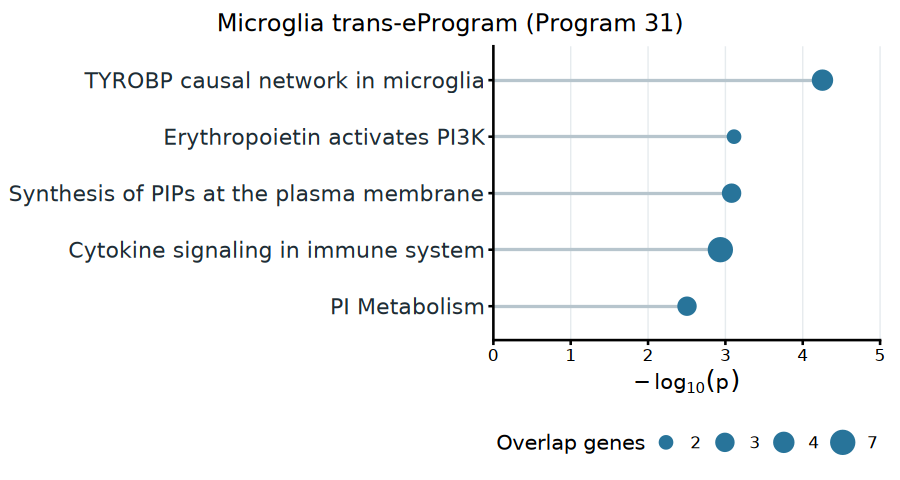

In [2]:
pw$label <- factor(pw$label, levels = rev(pw$label))

p <- ggplot(pw, aes(x = neglog10_p, y = label)) +
  geom_segment(aes(x = 0, xend = neglog10_p, yend = label), colour = "#B7C5CD", linewidth = 0.7) +
  geom_point(aes(size = overlap_n), colour = "#28749A") +
  scale_size_continuous(name = "Overlap genes", range = c(3, 6), breaks = sort(unique(pw$overlap_n))) +
  scale_x_continuous(limits = c(0, 5), expand = expansion(mult = c(0, 0))) +
  labs(title = "Microglia trans-eProgram (Program 31)", x = expression(-log[10](italic(p))), y = NULL) +
  theme_classic(base_size = 12) +
  theme(plot.title = element_text(size = 14, hjust = 0.5), plot.title.position = "plot", plot.margin = margin(8, 12, 8, 12),
        axis.text.y = element_text(size = 13, colour = "#1F2D35"),
        panel.grid.major.x = element_line(colour = "#E6EBEE", linewidth = 0.3),
        legend.position = "bottom")

options(repr.plot.width = 7.5, repr.plot.height = 4)
p